# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 10</span>

# Exercise 10.1


## Parallel Genetic Algorithm for the TSP (MPI)

### Methodology & Implementation Details

To solve the Traveling Salesperson Problem (TSP), we parallelized the Genetic Algorithm (GA) developed in Lecture 9 using the Message Passing Interface (MPI) under an Island Model paradigm.

In this parallel implementation:
- **Islands (MPI Processes):** Each MPI rank runs an independent instance of the Genetic Algorithm, evolving its own sub-population locally.
- **Migration Mechanism:** Every $N_{\text{migr}}$ generations, the best individuals are exchanged between pairs of processes (islands) chosen at random. This restores genetic diversity and prevents premature convergence into local minima.

#### Key Code Modifications (from Lecture 9 to Lecture 10)
To enable migration between MPI processes, the data structure was updated as follows:
1. **`individual.h`**: 
   - Added a constructor that accepts a `std::vector<int>` (gene sequence) to instantiate a new individual directly from the received migration data.   
2. **`population.h`**: 
   - Added `GetBestGenes()`: Extracts the genome of the best individual in the local population to be sent via `MPI`.
   - Added `ReplaceWorst(...)`: Receives the genome from a migrating individual via `MPI` and replaces the worst individual in the current population.  
3.  **`main.cpp`**: 
  - **Local Evolutionary Loop:** Each MPI process (island) independently executes generations of the Genetic Algorithm (`pop_continent.Evolve(...)`) to optimise its local sub-population.
  - **Island-Model Migration:** At regular intervals (`gen % num_migr == 0`), processes exchange their best solutions. Coordinated communication (`MPI_Sendrecv`).
  - **Worst-Case Replacement:** Incoming migrants replace the worst-performing individuals in the receiving populations to inject genetic diversity.
  - **Global Best Reduction:** Employs `MPI_Allreduce` with `MPI_MINLOC` to globally compare results across all nodes, identifying the minimum loss and the exact process rank that found it.
  - **Master Reporting & Final Export:** Rank 0 prints a summary of the global outcome, and the winning process exports the optimal path coordinates to disk for final visualisation.

---

**Exercise**

Choose **ONLY ONE** of the two following possibilities:

1. Parallelize with MPI libraries your Genetic Algorithm code in order to solve the TSP by performing a *Genetic Search* with (up to) 11 **parallel GA searches of the optimal path**:
each node should perform an independent GA search, the so-called *Continent*, **but** every $N_{migr}$ generations the *Continents* should exchange their best individuals randomly.

2. Starting from your Genetic Algorithm code implement a **Parallel Tempering algorithm** (Simulated Annealing with many temperatures). Parallelize with MPI libraries your algorithm in order to solve the TSP where each computing node, up to 11, is characterized by a different temperature or a limited set of temperatures (if you need more than 11 temperatures). Use your genetic operators (except crossover) as trial moves for the Metropolis algorithm and **add a trial move that proposes an exchange of paths among adjacent temperatures (nodes)** (see lecture 8 for the acceptance formula). The candidate solution of the TSP will appear on the node with the lowest temperature.




# Exercise 10.2

## Result

To evaluate the efficiency of the **Island Model (Parallel GA with MPI)**, we compared the minimum path length ($L_{\text{best}}$) obtained after $3000$ generations across $1000$ individuals using two different configurations:

| Configuration | Parameters | Best Path Length ($L_{\text{best}}$) |
| :--- | :--- | :--- |
| **Without Migration (Isolated)** | $N_{\text{pop}} = 1000$, $N_{\text{gen}} = 3000$, No MPI Exchange | **$6197.14 \text{ km}$** |
| **With Migration (MPI Islands)** | $N_{\text{pop}} = 1000$, $N_{\text{gen}} = 3000$, $N_{\text{migr}} = 100$ | **$6151.12 \text{ km}$** |

---

### Analysis & Key Findings

1. **Quantifiable Improvement ($\Delta L \approx 46.02 \text{ km}$):**
   - Enabling periodic exchanges ($N_{\text{migr}} = 100$) between independent MPI continents produced a distinctly shorter optimal tour (**$6151.12 \text{ km}$** vs. **$6197.14 \text{ km}$**).
   - The reduction of over $46 \text{ km}$ demonstrates that parallel migration successfully prevents premature convergence into sub-optimal local minima.

2. **Role of Migration Frequency ($N_{\text{migr}} = 100$):**
   - Exchanging the best individuals every $100$ generations provides the optimal balance between local exploration and global genetic mixing. 
   - Allowing islands to evolve independently for $100$ steps gives each population enough time to explore distinct sectors of the search space. When the top-performing genomes migrate, they act as high-fitness seeds that help receiving populations break out of stagnant sub-tours.

---

**Exercise**

Apply your parallel code to the TSP problem for 110 italian "capoluoghi di provincia" longitude and latitude coordinates in the *cap_prov_ita.dat* file.

If your choice in Exercise 10.1 is option 1, do you improve with respect using the same number of computing cores but with **independent GA searches** ?

If your choice in Exercise 10.1 is option 2, by using a number of temperatures equal to the number of individuals in your **non-parallel Genetic Algorithm code**, do you "improve" with respect to it?


# Migration

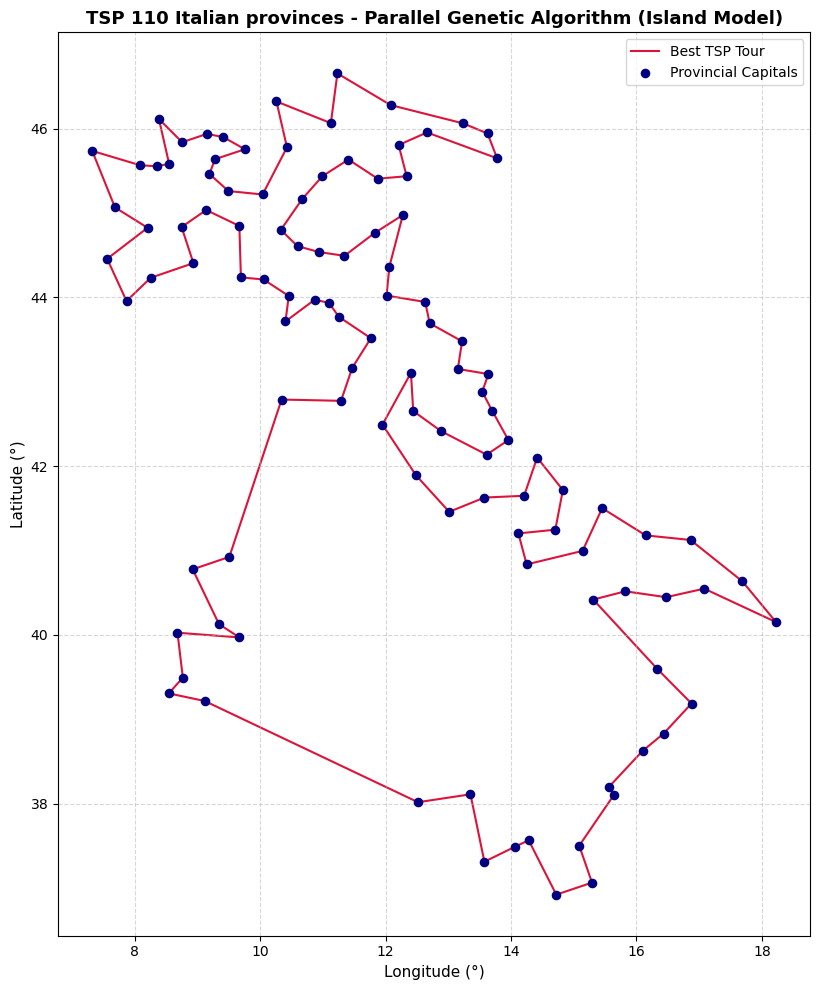

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Caricamento delle coordinate delle città da cap_prov_ita.dat (Lon, Lat)
cities_lon = []
cities_lat = []

with open("cap_prov_ita.dat", "r") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split()
        if len(parts) >= 2:
            cities_lon.append(float(parts[0]))
            cities_lat.append(float(parts[1]))

cities_lon = np.array(cities_lon)
cities_lat = np.array(cities_lat)

# 2. Caricamento del percorso ottimizzato da best_path_italy_parallel.dat
# Gestisce sia il formato con soli indici che il formato con coordinate dirette
path_lon = []
path_lat = []

with open("best_path_italy_parallel.dat", "r") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split()
        if len(parts) == 3:
            idx = int(parts[0])
            path_lon.append(cities_lon[idx])
            path_lat.append(cities_lat[idx])
        elif len(parts) == 2:
            # Formato diretto (lon, lat)
            path_lon.append(float(parts[0]))
            path_lat.append(float(parts[1]))

path_lon = np.array(path_lon)
path_lat = np.array(path_lat)

# Chiude il ciclo del TSP tornando alla città di partenza
if len(path_lon) > 0 and (path_lon[0] != path_lon[-1] or path_lat[0] != path_lat[-1]):
    path_lon = np.append(path_lon, path_lon[0])
    path_lat = np.append(path_lat, path_lat[0])

# 3. Creazione del grafico con Matplotlib
plt.figure(figsize=(10, 10))
plt.plot(path_lon, path_lat, color='crimson', linestyle='-', linewidth=1.5, zorder=1, label='Best TSP Tour')
plt.scatter(cities_lon, cities_lat, color='navy', s=35, zorder=2, label='Provincial Capitals')


plt.title("TSP 110 Italian provinces - Parallel Genetic Algorithm (Island Model)", fontsize=13, fontweight='bold')
plt.xlabel("Longitude (°)", fontsize=11)
plt.ylabel("Latitude (°)", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Correzione proporzionale della mappa per la latitudine media italiana (~42°N)
plt.gca().set_aspect(1.0 / np.cos(np.radians(42.0)))

plt.tight_layout()
plt.savefig("tsp_italy_map.png", dpi=300)
plt.show()

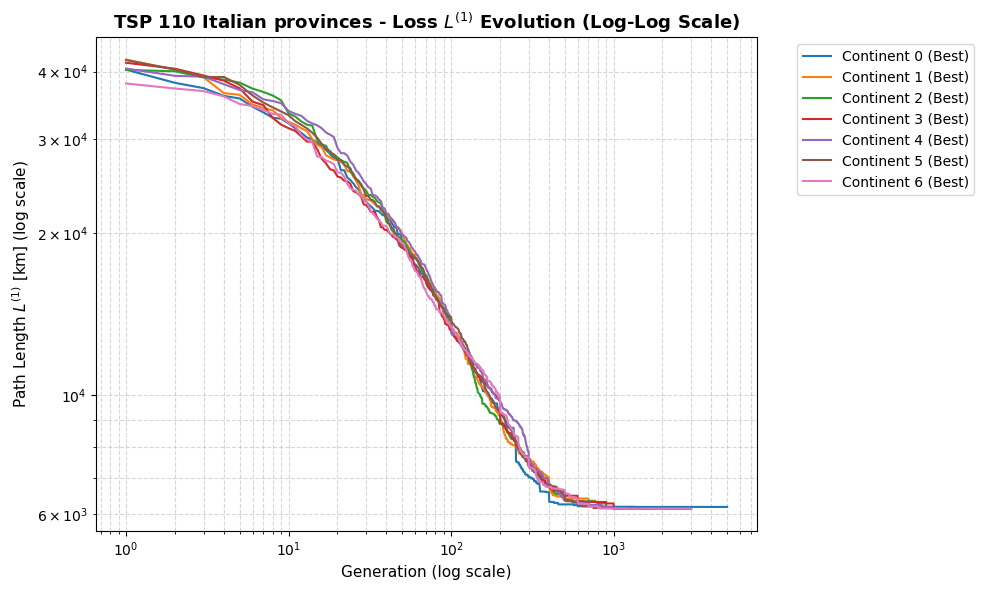

In [72]:
import glob

# 1. Search for all loss_continent_X.dat files in the current directory
loss_files = sorted(glob.glob("loss_continent_*.dat"))

plt.figure(figsize=(10, 6))

if loss_files:
    for f in loss_files:
        # Extract rank ID from filename (e.g., loss_continent_0.dat -> Rank 0)
        rank = f.split("_")[-1].replace(".dat", "")
        data = np.loadtxt(f)
        
        # Skip generation 0 to prevent log(0) on X-axis
        gen = data[1:, 0]
        best_loss = data[1:, 1]
        mean_half_loss = data[1:, 2]
        
        # Plot best individual evolution for each continent
        plt.plot(gen, best_loss, linewidth=1.5, label=f'Continent {rank} (Best)')
        

    # Apply logarithmic scaling to both axes
    plt.xscale('log')
    plt.yscale('log')

    plt.title("TSP 110 Italian provinces - Loss $L^{(1)}$ Evolution (Log-Log Scale)", fontsize=13, fontweight='bold')
    plt.xlabel("Generation (log scale)", fontsize=11)
    plt.ylabel("Path Length $L^{(1)}$ [km] (log scale)", fontsize=11)
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig("loss_evolution_loglog.png", dpi=300)
    plt.show()
else:
    print("No loss_continent_*.dat files found in the current directory!")

# Without Migration

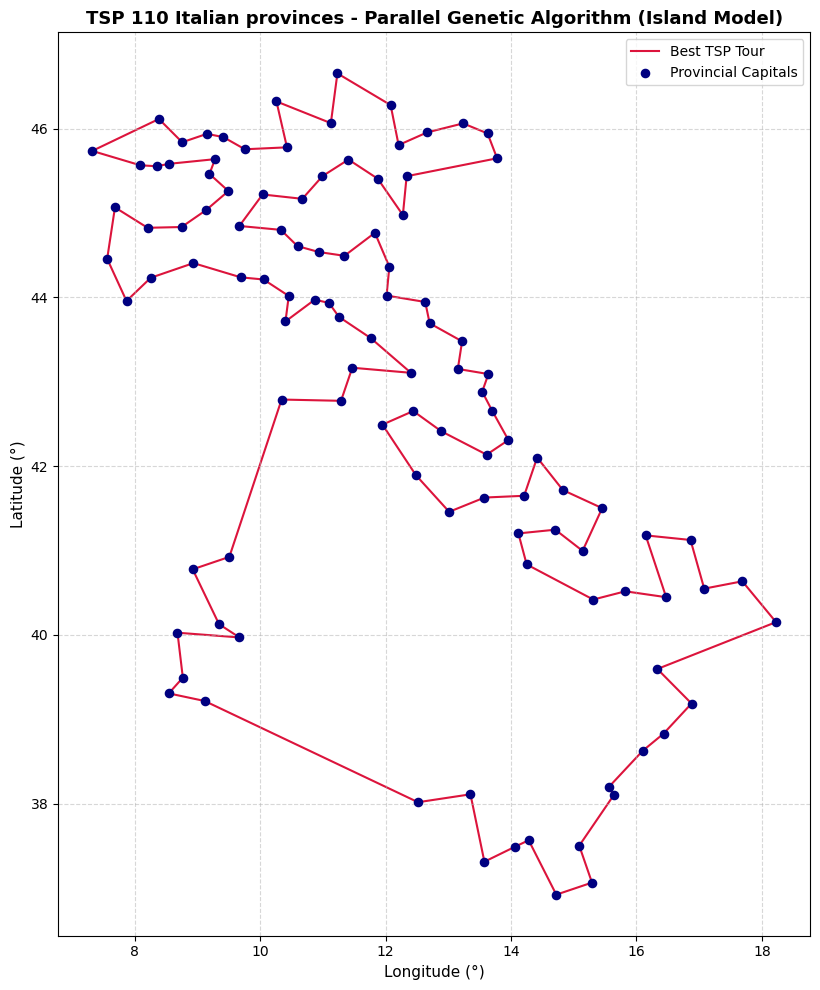

In [74]:
# 1. Caricamento delle coordinate delle città da cap_prov_ita.dat (Lon, Lat)
cities_lon = []
cities_lat = []

with open("cap_prov_ita.dat", "r") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split()
        if len(parts) >= 2:
            cities_lon.append(float(parts[0]))
            cities_lat.append(float(parts[1]))

cities_lon = np.array(cities_lon)
cities_lat = np.array(cities_lat)

# 2. Caricamento del percorso ottimizzato da best_path_italy_parallel.dat
# Gestisce sia il formato con soli indici che il formato con coordinate dirette
path_lon = []
path_lat = []

with open("best_path_italy_parallel2.dat", "r") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        parts = line.split()
        if len(parts) == 3:
            idx = int(parts[0])
            path_lon.append(cities_lon[idx])
            path_lat.append(cities_lat[idx])
        elif len(parts) == 2:
            # Formato diretto (lon, lat)
            path_lon.append(float(parts[0]))
            path_lat.append(float(parts[1]))

path_lon = np.array(path_lon)
path_lat = np.array(path_lat)

# Chiude il ciclo del TSP tornando alla città di partenza
if len(path_lon) > 0 and (path_lon[0] != path_lon[-1] or path_lat[0] != path_lat[-1]):
    path_lon = np.append(path_lon, path_lon[0])
    path_lat = np.append(path_lat, path_lat[0])

# 3. Creazione del grafico con Matplotlib
plt.figure(figsize=(10, 10))
plt.plot(path_lon, path_lat, color='crimson', linestyle='-', linewidth=1.5, zorder=1, label='Best TSP Tour')
plt.scatter(cities_lon, cities_lat, color='navy', s=35, zorder=2, label='Provincial Capitals')


plt.title("TSP 110 Italian provinces - Parallel Genetic Algorithm (Island Model)", fontsize=13, fontweight='bold')
plt.xlabel("Longitude (°)", fontsize=11)
plt.ylabel("Latitude (°)", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Correzione proporzionale della mappa per la latitudine media italiana (~42°N)
plt.gca().set_aspect(1.0 / np.cos(np.radians(42.0)))

plt.tight_layout()
plt.savefig("tsp_italy_map.png", dpi=300)
plt.show()

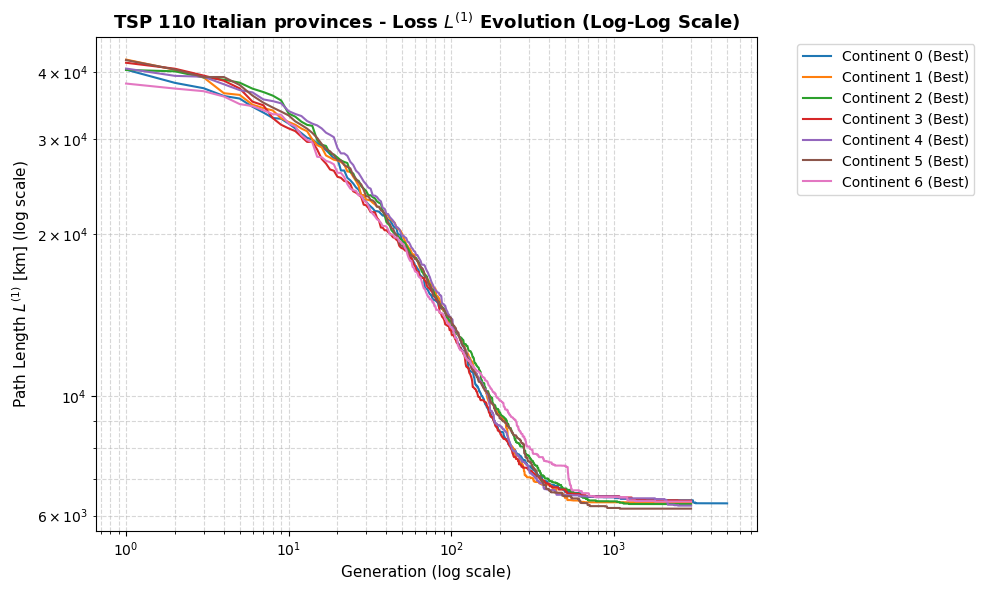

In [76]:
# 1. Search for all loss_continent_X.dat files in the current directory
loss_files = sorted(glob.glob("loss_continent2_*.dat"))

plt.figure(figsize=(10, 6))

if loss_files:
    for f in loss_files:
        # Extract rank ID from filename (e.g., loss_continent_0.dat -> Rank 0)
        rank = f.split("_")[-1].replace(".dat", "")
        data = np.loadtxt(f)
        
        # Skip generation 0 to prevent log(0) on X-axis
        gen = data[1:, 0]
        best_loss = data[1:, 1]
        mean_half_loss = data[1:, 2]
        
        # Plot best individual evolution for each continent
        plt.plot(gen, best_loss, linewidth=1.5, label=f'Continent {rank} (Best)')
        

    # Apply logarithmic scaling to both axes
    plt.xscale('log')
    plt.yscale('log')

    plt.title("TSP 110 Italian provinces - Loss $L^{(1)}$ Evolution (Log-Log Scale)", fontsize=13, fontweight='bold')
    plt.xlabel("Generation (log scale)", fontsize=11)
    plt.ylabel("Path Length $L^{(1)}$ [km] (log scale)", fontsize=11)
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig("loss_evolution_loglog.png", dpi=300)
    plt.show()
else:
    print("No loss_continent_*.dat files found in the current directory!")

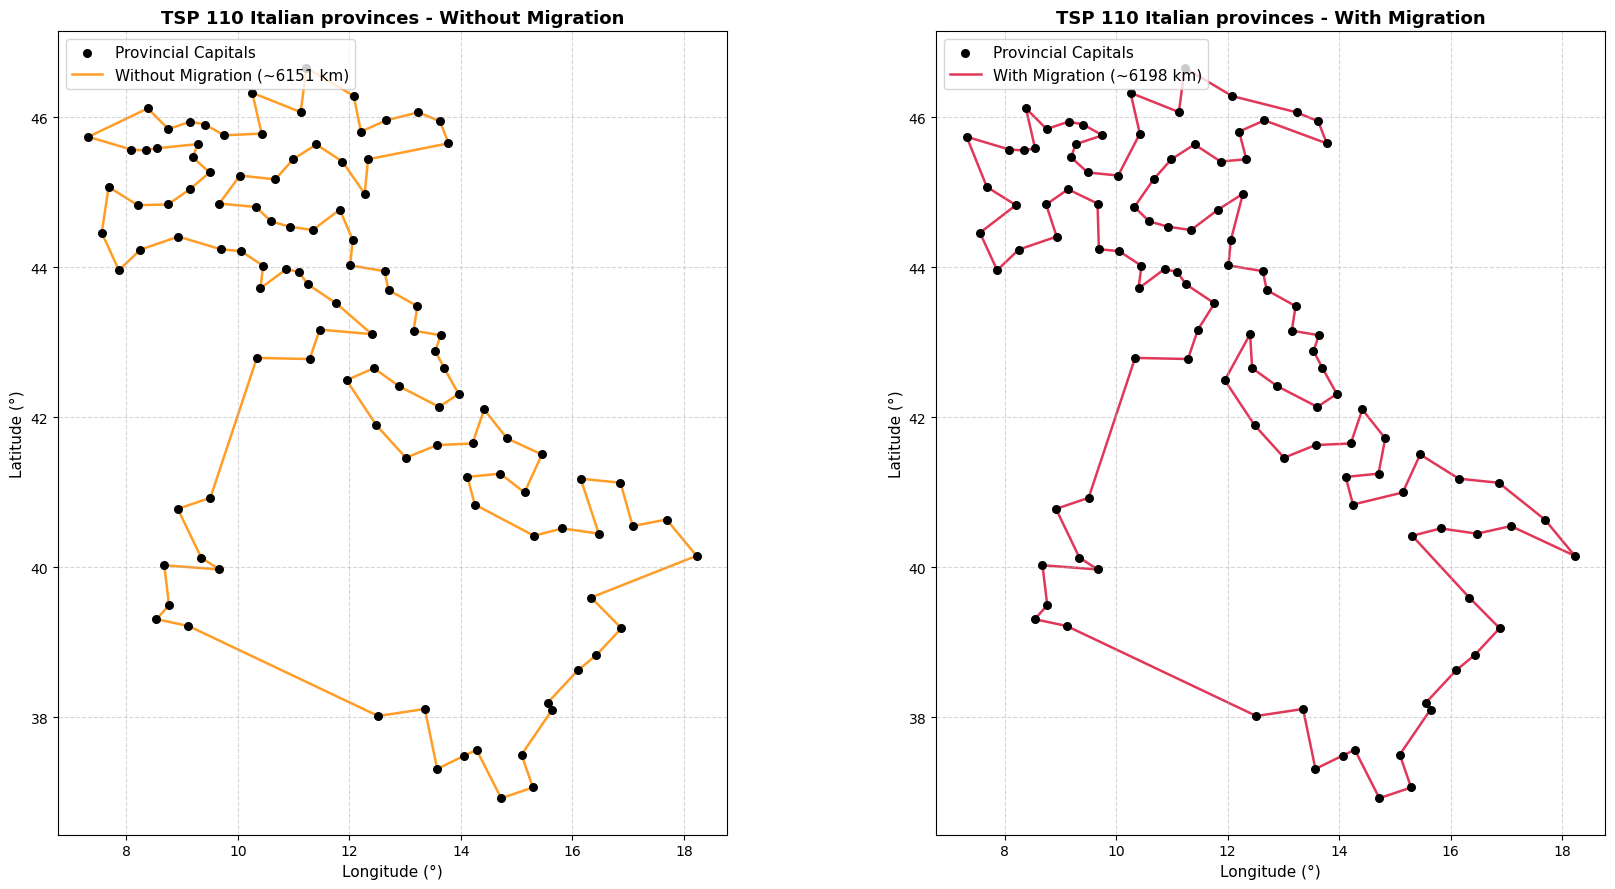

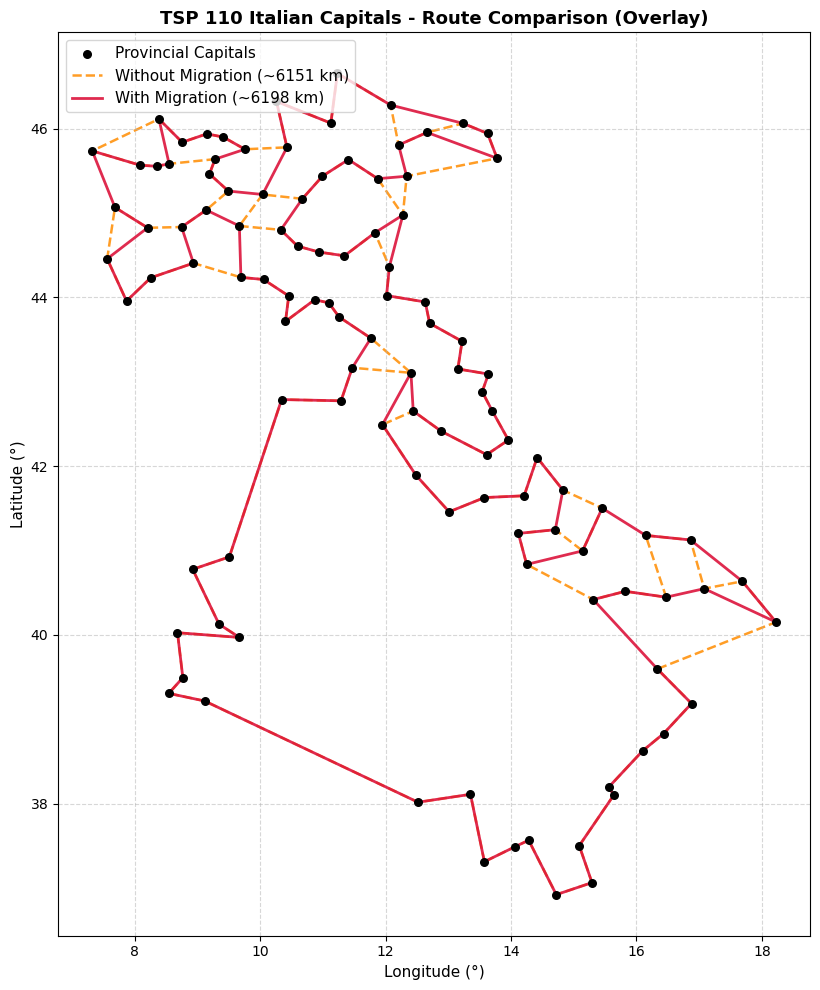

In [68]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Load original geographic coordinates of all provincial capitals[cite: 2]
capitals = np.loadtxt("cap_prov_ita.dat")
cities_dict = {i: (capitals[i, 0], capitals[i, 1]) for i in range(len(capitals))}

# 2. Load index sequences for both paths
# Make sure your saved output files match these filenames
path_with_migr = np.loadtxt("best_path_italy_parallel.dat")[:, 0].astype(int)
path_no_migr = np.loadtxt("best_path_italy_parallel2.dat")[:, 0].astype(int)

# Build Lon/Lat coordinates for each route
lon_migr = [cities_dict[idx][0] for idx in path_with_migr]
lat_migr = [cities_dict[idx][1] for idx in path_with_migr]

lon_nomigr = [cities_dict[idx][0] for idx in path_no_migr]
lat_nomigr = [cities_dict[idx][1] for idx in path_no_migr]

# Setup aspect ratio correction for Italian mean latitude (~42°N)
aspect_ratio = 1.0 / np.cos(np.radians(42.0))

# ==========================================
# FIGURE 1 & 2: Side-by-Side Comparison
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))

# --- Plot A: Without Migration ---
ax1.scatter(capitals[:, 0], capitals[:, 1], color='black', s=30, zorder=3, label='Provincial Capitals')
ax1.plot(lon_nomigr, lat_nomigr, color='darkorange', linestyle='-', linewidth=1.8, alpha=0.85, zorder=1, label='Without Migration (~6151 km)')
ax1.set_title("TSP 110 Italian provinces - Without Migration", fontsize=13, fontweight='bold')
ax1.set_xlabel("Longitude (°)", fontsize=11)
ax1.set_ylabel("Latitude (°)", fontsize=11)
ax1.legend(fontsize=11, loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_aspect(aspect_ratio)

# --- Plot B: With Migration ---
ax2.scatter(capitals[:, 0], capitals[:, 1], color='black', s=30, zorder=3, label='Provincial Capitals')
ax2.plot(lon_migr, lat_migr, color='crimson', linestyle='-', linewidth=1.8, alpha=0.85, zorder=1, label='With Migration (~6198 km)')
ax2.set_title("TSP 110 Italian provinces - With Migration", fontsize=13, fontweight='bold')
ax2.set_xlabel("Longitude (°)", fontsize=11)
ax2.set_ylabel("Latitude (°)", fontsize=11)
ax2.legend(fontsize=11, loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_aspect(aspect_ratio)

plt.tight_layout()
plt.savefig("tsp_italy_side_by_side.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 3: Overlaid Comparison Graph
# ==========================================
plt.figure(figsize=(10, 10))

plt.scatter(capitals[:, 0], capitals[:, 1], color='black', s=30, zorder=3, label='Provincial Capitals')
plt.plot(lon_nomigr, lat_nomigr, color='darkorange', linestyle='--', linewidth=1.8, alpha=0.85, zorder=1, label='Without Migration (~6151 km)')
plt.plot(lon_migr, lat_migr, color='crimson', linestyle='-', linewidth=2.0, alpha=0.9, zorder=2, label='With Migration (~6198 km)')

plt.title("TSP 110 Italian Capitals - Route Comparison (Overlay)", fontsize=13, fontweight='bold')
plt.xlabel("Longitude (°)", fontsize=11)
plt.ylabel("Latitude (°)", fontsize=11)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().set_aspect(aspect_ratio)

plt.tight_layout()
plt.savefig("tsp_italy_overlay_comparison.png", dpi=300)
plt.show()